# Lesson 1: Cleaning the squat landmark data and extracting features

This notebook walks through the first two steps of the H1 plan:

1. **Load the dataset and clean it** (remove frames with no body detected, check the files are what we expect).
2. **Extract features**: per-frame measurements (knee angle, hip-below-knee drop), then summarise each video into **one row** so it can go into logistic regression.

By the end you have a table `features.csv` with 240 rows (one per video), a few numeric columns, and a `label` column (Valid / Invalid). Model training happens in the next lesson.

Every step says **why** it's done, so you can explain the choices in your H2 report and the H3 interview.

> **Data location.** Unzip `Plan_A.zip` so that `fit1061_h2/data/Squat_Data/Squat_Data/Valid/...` and `.../Invalid/...` exist. The `data/` folder is git-ignored, so the 21k raw files stay out of the repository.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

DATA_DIR = os.path.join("data", "Squat_Data", "Squat_Data")
CLASSES = ["Valid", "Invalid"]
print("Data folder found:", os.path.isdir(DATA_DIR))

Data folder found: True


## Part A: understand the raw data before touching it

The data comes in three layers, and you need all three clear before cleaning anything:

| Level | What it is | How it's stored |
|---|---|---|
| Video | one recorded squat | a folder, e.g. `Valid/17/` |
| Frame | one moment in the video | a file, e.g. `Valid/17/42.npy` |
| Landmark values | 33 body points × (x, y, z, visibility) | a 132-number array inside the file |

So the 132 numbers are laid out as `[x0, y0, z0, v0, x1, y1, z1, v1, ..., x32, y32, z32, v32]`. Reshaping to `(33, 4)` makes landmark *i* simply row *i*.

MediaPipe Pose landmark indices we care about:

| Index | Landmark | Index | Landmark |
|---|---|---|---|
| 11 / 12 | left / right shoulder | 25 / 26 | left / right knee |
| 23 / 24 | left / right hip | 27 / 28 | left / right ankle |

**Coordinate system:** `x` and `y` are fractions of the image width/height (0 to 1). **`y` grows downwards**: a larger `y` means *lower* in the picture. This is the most common source of sign bugs. "Hip below knee" means `hip_y > knee_y`.

In [2]:
# Count videos and frames per class
for c in CLASSES:
    vids = os.listdir(os.path.join(DATA_DIR, c))
    n_frames = [len(os.listdir(os.path.join(DATA_DIR, c, v))) for v in vids]
    print(f"{c:8s} videos={len(vids)}  frames per video: min={min(n_frames)}, "
          f"median={int(np.median(n_frames))}, max={max(n_frames)}")

sample = np.load(os.path.join(DATA_DIR, "Valid", "0", "0.npy"))
print("\nOne frame:", sample.shape, sample.dtype)
print("Landmark 0 (nose) x, y, z, visibility:", sample.reshape(33, 4)[0].round(3))

Valid    videos=120  frames per video: min=60, median=85, max=161
Invalid  videos=120  frames per video: min=47, median=75, max=191

One frame: (132,) float64
Landmark 0 (nose) x, y, z, visibility: [ 0.509  0.223 -0.216  1.   ]


### Trap 1: file order

The frame files are named `0.npy, 1.npy, ..., 105.npy`. Sorting those names **as text** gives `0, 1, 10, 100, 101, ..., 11, ...`, which scrambles the video's timeline. The order matters a lot later, because we want the *lowest point* of the squat and the frames around it.

The fix is to load by number: `0.npy, 1.npy, 2.npy, ...` up to the frame count. The check below also confirms no frame numbers are missing.

In [3]:
print("Text sort (wrong):", sorted(os.listdir(os.path.join(DATA_DIR, "Valid", "0")))[:6])

def load_video(label, vid):
    # Load one video as an array of shape (n_frames, 132), in true frame order.
    folder = os.path.join(DATA_DIR, label, str(vid))
    n = len(os.listdir(folder))
    expected = {f"{i}.npy" for i in range(n)}
    assert set(os.listdir(folder)) == expected, f"missing/extra frame files in {folder}"
    return np.stack([np.load(os.path.join(folder, f"{i}.npy")) for i in range(n)])

raw = {(c, v): load_video(c, v) for c in CLASSES for v in range(120)}
print("Loaded", len(raw), "videos")

Text sort (wrong): ['0.npy', '1.npy', '10.npy', '100.npy', '101.npy', '102.npy']


Loaded 240 videos


## Part B: cleaning

We check four problems. For each one we **measure first, then decide**. Write down the numbers you get, since they go straight into your H2 report.

### B1. Empty frames (no body detected)

When MediaPipe can't find a person in a frame, the original author saved **132 zeros** (see their `extract_keypoints` function: `else np.zeros(33*4)`). If we keep those frames, a knee angle computed from (0,0) points is meaningless, and a hip `y` of 0 would look like the person jumped to the top of the image.

In [4]:
def is_empty(frames):
    return np.abs(frames).sum(axis=1) == 0

where = {"first frame": 0, "middle": 0, "last frame": 0}
videos_with_empty = 0
for (c, v), X in raw.items():
    idx = np.where(is_empty(X))[0]
    videos_with_empty += len(idx) > 0
    for i in idx:
        where["first frame" if i == 0 else "last frame" if i == len(X) - 1 else "middle"] += 1

print("Videos containing empty frames:", videos_with_empty, "/ 240")
print("Where the empty frames are:", where)

Videos containing empty frames: 236 / 240
Where the empty frames are: {'first frame': 236, 'middle': 16, 'last frame': 0}


Nearly every video has an empty **first** frame. That's a recording artefact (the detector hadn't locked on yet), so dropping it is safe. A handful of empty frames sit in the middle of a video; we drop those too. We do **not** fill them in (interpolate), because every summary feature we use only needs the remaining frames.

### B2. Low-visibility landmarks

Each landmark has a `visibility` score (0 to 1): how confident MediaPipe is that the point is visible. If a knee is hidden, its x/y is a guess. We check the six lower-body points we actually use.

In [5]:
LOWER_BODY = [23, 24, 25, 26, 27, 28]
VIS_THRESHOLD = 0.5

all_vis = np.concatenate([X[~is_empty(X)].reshape(-1, 33, 4)[:, LOWER_BODY, 3].min(axis=1)
                          for X in raw.values()])
print(f"Frames checked: {len(all_vis)}")
print(f"Frames where some hip/knee/ankle has visibility < {VIS_THRESHOLD}: {(all_vis < VIS_THRESHOLD).sum()}")
print(f"Lowest visibility seen: {all_vis.min():.3f}")

Frames checked: 21199
Frames where some hip/knee/ankle has visibility < 0.5: 0
Lowest visibility seen: 0.868


On this dataset the answer is **zero** frames. We still keep the filter in the cleaning function: it costs nothing, and it protects the pipeline if it's ever run on new recordings (e.g. a patient filmed at home with a knee out of shot). Saying "I checked, and none failed" is stronger in a report than not checking.

### B3. Duplicate videos

If the same recording appears twice (or in both classes), it would leak between train and test later. We fingerprint each video's numbers and look for repeats.

In [6]:
seen, dups = {}, []
for key, X in raw.items():
    fp = hash(X.round(5).tobytes())
    if fp in seen:
        dups.append((key, seen[fp]))
    seen[fp] = key
print("Exact duplicate videos:", dups if dups else "none")

Exact duplicate videos: none


### B4. Which values to keep

Each frame has `x, y, z, visibility`. Following the H1 assumption, we use only **`x` and `y`**:

- MediaPipe's `z` (depth) from a single camera is an estimate and much noisier than x/y.
- `visibility` is used for filtering (B2), not as a feature.

### The cleaning function

Everything above, in one function, applied to every video:

In [7]:
def clean_video(X, vis_threshold=VIS_THRESHOLD):
    # Return (n_good_frames, 33, 2) x/y array plus a small report of what was removed.
    n_raw = len(X)
    X = X[~is_empty(X)].reshape(-1, 33, 4)
    n_after_empty = len(X)
    X = X[X[:, LOWER_BODY, 3].min(axis=1) >= vis_threshold]
    report = {"n_raw": n_raw,
              "dropped_empty": n_raw - n_after_empty,
              "dropped_low_vis": n_after_empty - len(X),
              "n_clean": len(X)}
    return X[:, :, :2], report

clean, reports = {}, []
for (c, v), X in raw.items():
    clean[(c, v)], rep = clean_video(X)
    reports.append({"label": c, "video": v, **rep})

cleaning_report = pd.DataFrame(reports)
print(cleaning_report.groupby("label")[["n_raw", "dropped_empty", "dropped_low_vis", "n_clean"]].sum())
assert cleaning_report.n_clean.min() > 30, "a video lost too many frames"

         n_raw  dropped_empty  dropped_low_vis  n_clean
label                                                  
Invalid  10081            119                0     9962
Valid    11370            133                0    11237


## Part C: per-frame features

Now we turn 33 points into a few numbers that describe **squat depth**, the thing the labels appear to measure.

### C1. Knee angle

The angle at the knee between the thigh (knee → hip) and the shin (knee → ankle). Standing straight is about 180°, and a deeper squat gives a smaller angle.

For three points A (hip), B (knee), C (ankle):

$$\cos\theta = \frac{\vec{BA}\cdot\vec{BC}}{|\vec{BA}|\,|\vec{BC}|}$$

We compute it for both legs and average them. Averaging cancels some of the jitter from one side.

### C2. Hip-below-knee drop

Powerlifting depth rules ask whether the hip crease goes below the top of the knee. In image coordinates that's:

$$\text{drop} = \text{hip}_y - \text{knee}_y \quad (>0 \text{ means hip is lower than knee})$$

The raw drop depends on how far the lifter stood from the camera (closer means bigger body in the image means bigger numbers). So we **divide by torso length** (shoulder-to-hip distance in `y`), which makes it scale-free. This is the "drop scaled by torso length" feature from your H1 risk register.

In [8]:
L_SH, R_SH, L_HIP, R_HIP, L_KNEE, R_KNEE, L_ANK, R_ANK = 11, 12, 23, 24, 25, 26, 27, 28

def joint_angle(a, b, c):
    # Angle ABC in degrees for arrays of points shaped (n_frames, 2).
    ba, bc = a - b, c - b
    cos = (ba * bc).sum(axis=1) / (np.linalg.norm(ba, axis=1) * np.linalg.norm(bc, axis=1) + 1e-9)
    return np.degrees(np.arccos(np.clip(cos, -1.0, 1.0)))   # clip guards against 1.0000001 rounding

def frame_features(P):
    # P: (n_frames, 33, 2) -> dict of per-frame arrays.
    knee_l = joint_angle(P[:, L_HIP], P[:, L_KNEE], P[:, L_ANK])
    knee_r = joint_angle(P[:, R_HIP], P[:, R_KNEE], P[:, R_ANK])
    hip_y = P[:, [L_HIP, R_HIP], 1].mean(axis=1)
    knee_y = P[:, [L_KNEE, R_KNEE], 1].mean(axis=1)
    shoulder_y = P[:, [L_SH, R_SH], 1].mean(axis=1)
    return {"knee_angle": (knee_l + knee_r) / 2,
            "drop": hip_y - knee_y,
            "torso": hip_y - shoulder_y}

# Sanity check on a known point: a right angle should give 90 degrees
print(joint_angle(np.array([[0, 1.]]), np.array([[0, 0.]]), np.array([[1, 0.]])))

[90.]


### Look at it before trusting it

Plot one Valid and one Invalid video over time. You should see the knee angle start high (standing), dip at the bottom of the squat, and come back up. If the curve looks like noise, something upstream is wrong (for example, the text-sort bug).

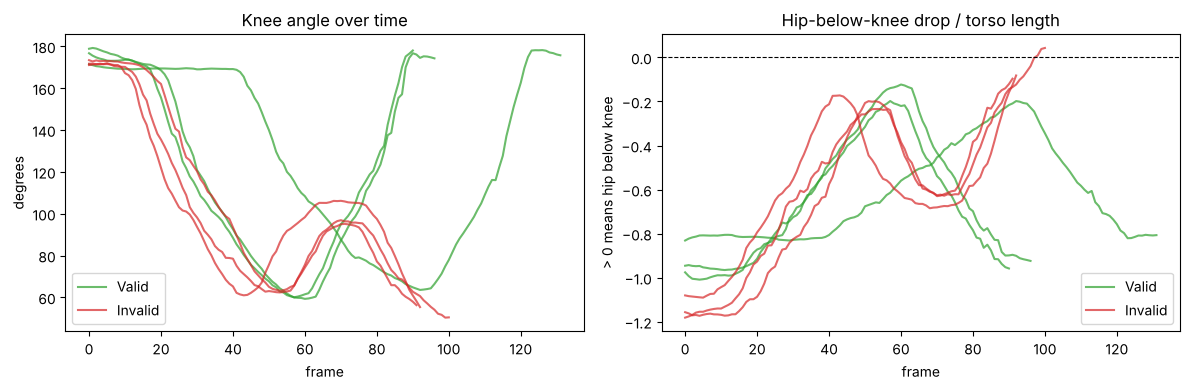

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for c, colour in zip(CLASSES, ["tab:green", "tab:red"]):
    for v in [0, 1, 2]:
        f = frame_features(clean[(c, v)])
        axes[0].plot(f["knee_angle"], color=colour, alpha=0.7, label=c if v == 0 else None)
        axes[1].plot(f["drop"] / np.median(f["torso"]), color=colour, alpha=0.7, label=c if v == 0 else None)
axes[0].set(title="Knee angle over time", xlabel="frame", ylabel="degrees")
axes[1].axhline(0, color="k", lw=0.8, ls="--")
axes[1].set(title="Hip-below-knee drop / torso length", xlabel="frame", ylabel="> 0 means hip below knee")
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

## Part D: one row per video

Logistic regression needs a fixed-length input, but videos have 46 to 190 frames. So each video's time series gets **summarised** into a few numbers that describe its deepest point.

| Feature | Meaning | Why |
|---|---|---|
| `min_knee` | smallest knee angle in the video | the obvious depth measure; also the **threshold baseline** |
| `low5_knee` | median of the 5 smallest knee angles | same idea, but one glitchy frame can't control it (H1 noise mitigation) |
| `max_drop_norm` | largest hip-below-knee drop ÷ median torso length | the depth rule, made scale-free |
| `low5_drop_norm` | median of the 5 largest drops ÷ torso | robust version of the above |
| `final_knee` | median knee angle over the last 5 frames | did the lifter **stand back up**? (Part E explains why this is needed) |

We also save a **body signature** for the grouped split from H1 (risk 1): `torso_thigh_ratio`, the torso length over the thigh length, measured in the **standing** frames (knee angle > 160°). It's measured standing because in a front view the thigh looks shorter as the lifter descends. This column is **not a model input**. It's only used to group videos that probably show the same person.

### What we deliberately leave out

- **Number of frames.** Valid videos are on average about 10 frames longer. A model could learn "long video means valid", which is a property of how the clips were cut, not of the squat. Including it would make the scores look better for the wrong reason, so we keep `n_clean` only for reporting.
- **No scaling or label use here.** Every feature is computed from one video alone and never looks at the label or other videos. That makes it safe to compute before the train/test split. **Standardisation (mean/std) does depend on other videos**, so it must be fitted inside the training folds later, not here.

In [10]:
K = 5   # frames used for the "robust" low/high summaries

def video_features(P):
    f = frame_features(P)
    torso = np.median(f["torso"])
    knee_sorted = np.sort(f["knee_angle"])
    drop_sorted = np.sort(f["drop"])

    standing = f["knee_angle"] > 160
    if standing.sum() < 3:                       # fall back to the 10% straightest frames
        standing = f["knee_angle"] >= np.quantile(f["knee_angle"], 0.9)
    S = P[standing]
    hip = S[:, [L_HIP, R_HIP]].mean(axis=1)
    knee = S[:, [L_KNEE, R_KNEE]].mean(axis=1)
    shoulder = S[:, [L_SH, R_SH]].mean(axis=1)
    thigh_len = np.linalg.norm(hip - knee, axis=1)
    torso_len = np.linalg.norm(shoulder - hip, axis=1)

    return {"min_knee": knee_sorted[0],
            "low5_knee": np.median(knee_sorted[:K]),
            "max_drop_norm": drop_sorted[-1] / torso,
            "low5_drop_norm": np.median(drop_sorted[-K:]) / torso,
            "final_knee": np.median(f["knee_angle"][-K:]),
            "torso_thigh_ratio": np.median(torso_len / thigh_len),
            "n_clean": len(P)}

rows = [{"video_id": f"{c}_{v}", "label": c, **video_features(P)} for (c, v), P in clean.items()]
features = pd.DataFrame(rows)
features["y"] = (features.label == "Invalid").astype(int)   # invalid = positive class (H1)
features.head()

,video_id,label,min_knee,low5_knee,max_drop_norm,low5_drop_norm,final_knee,torso_thigh_ratio,n_clean,y
0,Valid_0,Valid,63.544631,63.966193,-0.198223,-0.207049,176.734237,1.365118,132,0
1,Valid_1,Valid,60.047981,60.487689,-0.198041,-0.210707,175.120466,1.318576,91,0
2,Valid_2,Valid,59.279070,59.701409,-0.123085,-0.130758,174.723219,1.288742,97,0
3,Valid_3,Valid,53.201989,54.155666,-0.085158,-0.096734,177.610685,1.302733,92,0
4,Valid_4,Valid,53.812206,54.776936,0.002729,-0.005080,173.343197,1.331499,91,0


## Part E: check the features

Three checks before moving on:

1. **No missing or infinite values.** A division by a zero torso would show up here.
2. **Do the classes actually differ?** Compare class means and the overlap.
3. **Are the features redundant?** H1 rejected Naive Bayes because these features are correlated. Here we measure how strongly.

In [11]:
MODEL_FEATURES = ["min_knee", "low5_knee", "max_drop_norm", "low5_drop_norm", "final_knee"]

assert np.isfinite(features[MODEL_FEATURES + ["torso_thigh_ratio"]]).all().all()
print("Rows:", len(features), "| class counts:", features.label.value_counts().to_dict())
print()
print(features.groupby("label")[MODEL_FEATURES + ["n_clean"]].agg(["mean", "std"]).round(3).T)

Rows: 240 | class counts: {'Valid': 120, 'Invalid': 120}

label                Invalid    Valid
min_knee       mean   85.386   59.327
               std    16.226    8.199
low5_knee      mean   85.909   59.787
               std    16.021    8.095
max_drop_norm  mean   -0.336   -0.064
               std     0.163    0.080
low5_drop_norm mean   -0.343   -0.071
               std     0.159    0.079
final_knee     mean  153.915  172.092
               std    41.554    5.243
n_clean        mean   83.017   93.642
               std    29.196   23.310


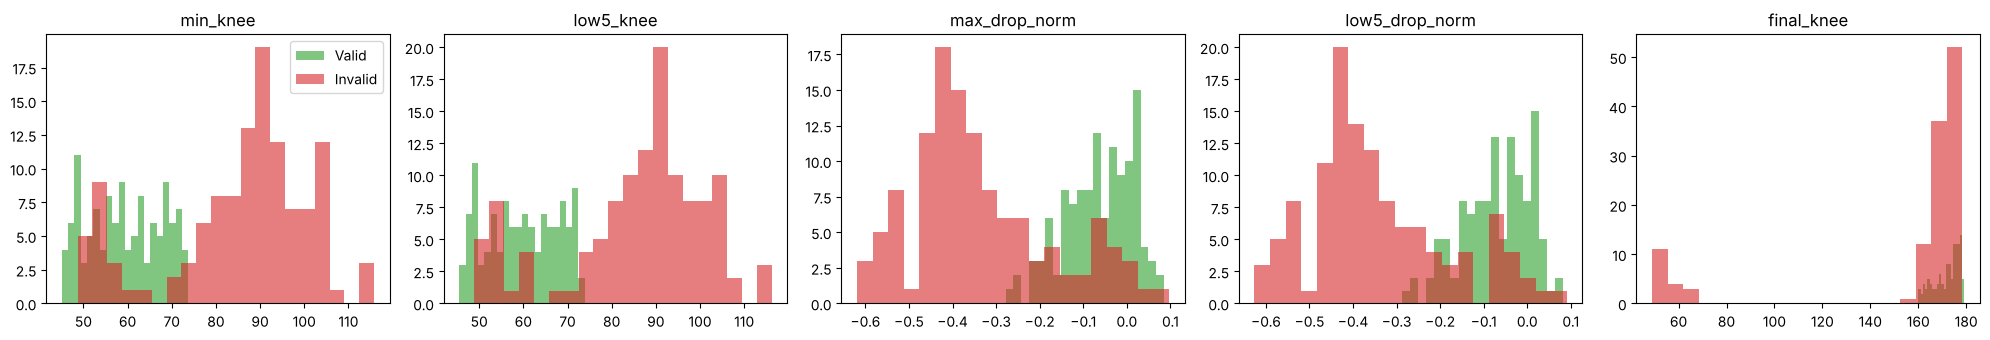

Correlation between features:
                min_knee  low5_knee  max_drop_norm  low5_drop_norm  final_knee
min_knee            1.00       1.00          -0.94           -0.94        0.30
low5_knee           1.00       1.00          -0.94           -0.94        0.29
max_drop_norm      -0.94      -0.94           1.00            1.00       -0.25
low5_drop_norm     -0.94      -0.94           1.00            1.00       -0.24
final_knee          0.30       0.29          -0.25           -0.24        1.00


In [12]:
fig, axes = plt.subplots(1, len(MODEL_FEATURES), figsize=(20, 3.5))
for ax, col in zip(axes, MODEL_FEATURES):
    for c, colour in zip(CLASSES, ["tab:green", "tab:red"]):
        ax.hist(features.loc[features.label == c, col], bins=20, alpha=0.6, color=colour, label=c)
    ax.set_title(col)
axes[0].legend()
plt.tight_layout(); plt.show()

print("Correlation between features:")
print(features[MODEL_FEATURES].corr().round(2))

### E2. A surprise: the Invalid class has more than one fault in it

In the Part C plot, the three Invalid examples didn't look like shallow squats. They went deep, half-rose, then sank again. Plotting many videos with time stretched to 0 to 1 (so clips of different lengths line up) shows the pattern clearly:

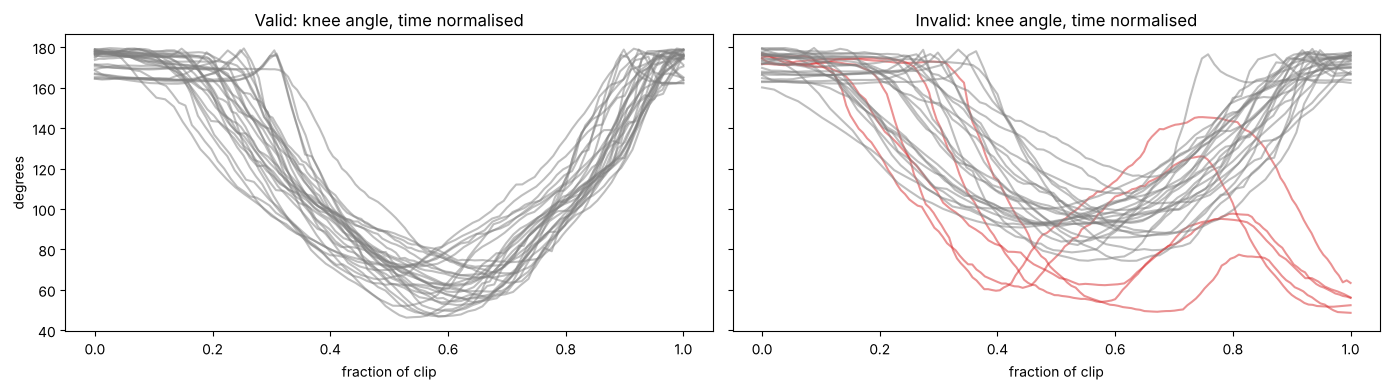

(depth cut used for the description: min_knee <= 73.7 deg)


pattern,deep + stands,fails to stand,shallow
label,,,
Invalid,4,18,98
Valid,120,0,0


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, c in zip(axes, CLASSES):
    for v in range(0, 120, 4):
        k = frame_features(clean[(c, v)])["knee_angle"]
        ax.plot(np.linspace(0, 1, len(k)), k, alpha=0.5, color="tab:red" if (c == "Invalid" and v < 18) else "tab:grey")
    ax.set(title=f"{c}: knee angle, time normalised", xlabel="fraction of clip")
axes[0].set_ylabel("degrees")
plt.tight_layout(); plt.show()

DEPTH_CUT = features.loc[features.label == "Valid", "min_knee"].max()   # deepest-valid boundary, just for this description
def fault_type(r):
    if r.final_knee < 140:
        return "fails to stand"
    return "deep + stands" if r.min_knee <= DEPTH_CUT else "shallow"
features["pattern"] = features.apply(fault_type, axis=1)
print(f"(depth cut used for the description: min_knee <= {DEPTH_CUT:.1f} deg)")
pd.crosstab(features.label, features.pattern)

**What this shows:**

- **Every Valid video** goes deep *and* stands back up.
- **Invalid** contains three groups:
  - mostly **shallow** squats (not deep enough), which is the depth rule from H1;
  - **18 videos that go deep but never stand back up** (a failed lift). These are all Invalid videos 0 to 17, recorded one after another;
  - **4 videos that look fine** on depth and standing. Their fault isn't visible in these features (possibly knee position, an early start, or a judging call). Expect the model to get these wrong. Name them as a known limitation and don't tune the model to chase them.

**Why it matters:** H1 assumed *"labels mainly reflect squat depth."* That's true for about 80% of Invalid videos but not all. A depth-only model (including the knee-threshold baseline) would call the 18 failed lifts **Valid**, because they *did* go deep. That's the exact error H1 ranked as most serious (an invalid squat passed as fine). So we add `final_knee`.

Put this in H2 under **"Pivot since H1"**: *"Data exploration showed 18 of 120 Invalid videos are failed lifts (deep, but the lifter does not stand), so I added a return-to-standing feature (`final_knee`). The knee-threshold baseline stays depth-only as planned, which makes the comparison show what the extra feature adds."*

Note: the `pattern` column is our *description* of the data, built after looking at the labels. It must **not** be used as a model input.

In [14]:
os.makedirs("outputs", exist_ok=True)
features.to_csv(os.path.join("outputs", "features.csv"), index=False)
cleaning_report.to_csv(os.path.join("outputs", "cleaning_report.csv"), index=False)
print("Saved outputs/features.csv and outputs/cleaning_report.csv")

Saved outputs/features.csv and outputs/cleaning_report.csv


## What to take from this lesson

**Cleaning findings (put these numbers in your H2 report):**
- 240 videos (120 / 120), 46 to 190 frames each after cleaning, with frame files loaded in numeric order.
- Empty frames: almost all at frame 0 (detector warm-up), plus a few mid-video, all dropped.
- Low-visibility lower-body landmarks: none found, but the filter is kept for robustness.
- No duplicate videos.

**Feature findings:**
- Invalid squats have a clearly larger minimum knee angle (shallower) and a more negative hip drop (hip stays above the knee). That fits the H1 assumption that the labels reflect depth.
- The classes **overlap** in the histograms. A single threshold won't be perfect, which is what makes the baseline-vs-logistic-regression comparison worth running.
- The **Invalid class is mixed**: ~98 shallow squats, 18 failed lifts (deep but don't stand), 4 with no visible fault. `final_knee` was added to catch the failed lifts.
- The knee features are almost perfectly correlated with each other (≈1.0), as are the two drop features. Knee vs drop is strong (|r| ≈ 0.94) but not complete. In the model lesson, watch what happens to the weights when near-duplicate features are both included. You'll likely end up picking one knee feature, one drop feature and `final_knee`.

**Limitations to state honestly:**
- **Front-view camera.** The 2D knee angle is a *projection*: from the front, a bent knee looks straighter than it really is. The values aren't true joint angles, but they are measured the same way in every video, so they still rank depth.
- **Aspect ratio.** x is a fraction of image width and y of image height. If the video isn't square, angles are slightly distorted. Again it's consistent across videos, but it's another reason the angle isn't anatomically exact.
- **`torso_thigh_ratio` is a heuristic** for grouping, not a real subject ID.

### Check yourself (likely H3 interview questions)
1. Why must frame files be loaded in numeric rather than text order?
2. Why is it safe to extract these features *before* the train/test split, but not safe to standardise them before it?
3. Why use the median of the 5 lowest knee angles instead of just the minimum?
4. Why divide the hip drop by torso length?
5. Why is the number of frames excluded from the model even though it differs between classes?
6. Why can't a knee-angle threshold alone ever exceed about 0.85 invalid recall on this data?
7. Why must the `pattern` column never be used as a model input?

**Next lesson:** grouped train/test split using `torso_thigh_ratio` (and why the failed lifts being recorded back to back matters for grouping), the majority-class and knee-threshold baselines, then logistic regression with 5-fold CV.